# GAM with cell-specific biases

Same analysis as the plain GAM notebook, with one bias per cell added to the model:

$$
F_i = s(x_i, y_i) + b_{c(i)} + \varepsilon_i
$$

- The biases $b_c$ are effectively unpenalized (`lam_cell` $\approx 0$). Each cell's overall level is absorbed by its bias, so the spatial field $s$ is informed only by differences between points of the same cell.
- Cells with a single measurement carry no within-cell information and are dropped.
- Baseline model: each cell's own mean ($F_i = b_{c(i)} + \varepsilon_i$), so $\Delta$ MSE measures what position explains beyond the cell average.
- Folds are built over points, dealing each cell's points to different folds, so every held-out point keeps at least one point of its cell in the training set (its bias is known).
- Tuning of the spatial $\lambda$, nested CV, $\Delta$ MSE and the significance test are unchanged.


# Load Data

In [1]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
import statsmodels.formula.api as smf
from pygam import LinearGAM
from pygam.terms import f as factor, s, te
from scipy.interpolate import BSpline
from scipy.stats import t, ttest_1samp
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import KFold
from statsmodels.tools.sm_exceptions import ConvergenceWarning
from tqdm.auto import tqdm

''' ---------------------------------------------------------------------------
    File description
'''

data = np.load(Path("..") / "data" / "mechanical_fingerprint.npz")

params = ["A", "B", "alpha", "beta", "E", "gamma"]
dirs = ["x", "y"]

log_params = {"A", "B", "E"}

dfs = {}

symmetry_x = 162.5

''' ---------------------------------------------------------------------------
    Symmetry and applying logarithm
'''

for d in dirs:
    coords_key = "coords_x_trans_ds_2" if d == "x" else "coords_y_trans_ds_2"
    coords = data[coords_key]

    df_d = pd.DataFrame({
        "cell_idx": data["cell_idx"],
        "cell_label": data["cell_label_in_day_folder"],
        "x_pos": coords[:, 0] - symmetry_x,
        "y_pos": coords[:, 1],
    })

    for p in params:
        values = data[f"{p}_{d}"]

        if p in log_params:
            df_d[f"log{p}"] = np.log(values)
        else:
            df_d[p] = values

    dfs[d] = df_d

''' ---------------------------------------------------------------------------
    Cleanup
'''

df_x = dfs["x"].replace([np.inf, -np.inf], np.nan).dropna()
df_y = dfs["y"].replace([np.inf, -np.inf], np.nan).dropna()

''' ---------------------------------------------------------------------------
    Cell Boundary Shape
'''

border_data = np.load(Path("..") / "data" / "actin_nucleus_borders.npz")
border_x = border_data['actin_border_x'] - symmetry_x
border_y = border_data['actin_border_y']

# Select Channel

points: 190  cells: 74


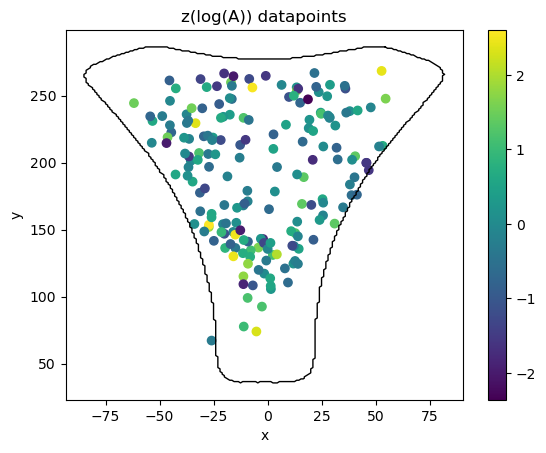

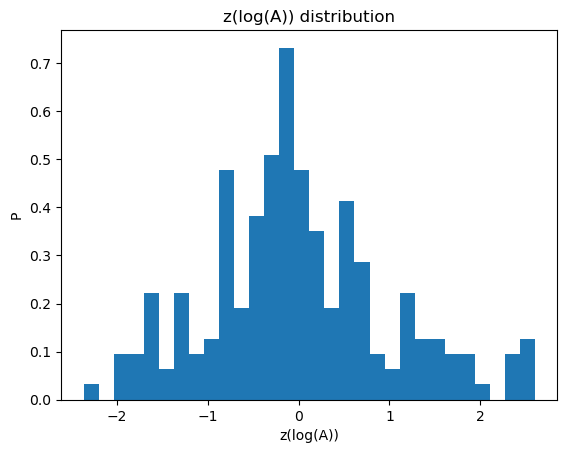

In [2]:
F_name = 'z(log(A))' # 'q1', 'z(log(A))', or 'z(log(E))'
df = df_x     # df_x or df_y

''' Drop cells with a single measurement (no within-cell information) '''

points_per_cell = df.groupby("cell_idx").cell_idx.transform("size")
df = df[points_per_cell >= 2]

cell = pd.factorize(df.cell_idx)[0]   # cell index 0 .. n_cells - 1

print("points:", len(df), " cells:", cell.max() + 1)


''' Python names for easy access '''

x = df.x_pos.to_numpy()
y = df.y_pos.to_numpy()

logA = df.logA.to_numpy()
logB = df.logB.to_numpy()
alpha = df.alpha.to_numpy()
beta = df.beta.to_numpy()
logE = df.logE.to_numpy()
gamma = df.gamma.to_numpy()

''' z normalized fields '''

logA = (logA - logA.mean()) / logA.std()
logB = (logB - logB.mean()) / logB.std()
alpha = (alpha - alpha.mean()) / alpha.std()
beta = (beta - beta.mean()) / beta.std()
logE = (logE - logE.mean()) / logE.std()
gamma = (gamma - gamma.mean()) / gamma.std()

q1 = (
    0.1688 * logA
    + 0.2758 * logB
    + 0.0091 * logE
    + 0.2694 * alpha
    + 0.2747 * beta
    + 0.0021 * gamma
)

''' Fied selection '''

FIELDS = {'q1': q1, 'z(log(A))': logA, 'z(log(E))': logE}
F = FIELDS[F_name]

''' Basic plotting '''

plt.scatter(x, y, c=F)
plt.xlabel("x")
plt.ylabel("y")
plt.title(f"{F_name} datapoints")
plt.colorbar()
plt.plot(border_x, border_y, '-k', lw=1)
plt.show()

plt.hist(F, bins=30, density=True)
plt.xlabel(F_name)
plt.ylabel("P")
plt.title(f"{F_name} distribution")
plt.show()

# Cell-specific biases

In [3]:
''' ---------------------------------------------------------------------------
    Cell-specific biases

    Model:     F_i = s(x_i, y_i) + b_cell(i) + noise
    Baseline:  F_i = b_cell(i) + noise          (each cell's own mean)

    The biases are effectively unpenalized (lam_cell ~ 0), so the spatial
    field is only informed by differences between points of the same cell.
    The fit functions use the globals n_splines and edge_knots.
'''

lam_cell = 1e-6


def cell_kfold(cells, n_splits, seed):
    ''' K-fold split over points. Each cell's points are dealt to different
        folds, so a held-out point always keeps at least one point of its
        cell in the training set. Cells with a single point are never held
        out (this happens in the inner CV, after the outer split). '''

    rng = np.random.default_rng(seed)
    fold_of_point = np.full(len(cells), -1)
    k = 0

    for c in rng.permutation(np.unique(cells)):
        idx = np.flatnonzero(cells == c)

        if len(idx) < 2:
            continue

        for i in rng.permutation(idx):
            fold_of_point[i] = k % n_splits
            k += 1

    return [
        (
            np.flatnonzero(fold_of_point != j),
            np.flatnonzero(fold_of_point == j),
        )
        for j in range(n_splits)
        if np.any(fold_of_point == j)
    ]


def fit_gam_cells(lam, x_, y_, cells_, F_):
    ''' Spatial GAM + cell biases, fitted on data mirrored around x = 0 '''

    X_sym_ = np.column_stack([
        np.concatenate([x_, -x_]),
        np.concatenate([y_, y_]),
        np.concatenate([cells_, cells_]),
    ])

    return LinearGAM(
        te(
            0,
            1,
            n_splines=[n_splines, n_splines],
            lam=[lam, lam],
            edge_knots=edge_knots,
        )
        + factor(2, lam=lam_cell)
    ).fit(
        X_sym_,
        np.concatenate([F_, F_]),
    )


def predict_gam_cells(gam, x_, y_, cells_):
    return gam.predict(np.column_stack([x_, y_, cells_]))


def cell_mean_prediction(F_train, cells_train, cells_test):
    ''' Baseline: each cell's mean over its training points '''
    means = pd.Series(F_train).groupby(cells_train).mean()
    return means.loc[cells_test].to_numpy()


def cell_biases(gam):
    return gam.coef_[gam.terms.get_coef_indices(1)]


def predict_field(gam, X_):
    ''' Spatial part only, offset by intercept + mean cell bias (data scale) '''
    X_cells_ = np.column_stack([X_, np.zeros(len(X_))])
    return (
        gam.partial_dependence(term=0, X=X_cells_)
        + gam.coef_[-1]
        + cell_biases(gam).mean()
    )


# Simple Cross Validation GAM tuning

In [4]:
n_splines = 15
n_folds = 30

lambda_grid = np.logspace(-5, 3, 30)

X = np.column_stack([x, y])

x_domain = np.concatenate([
    x,
    -x,
    border_x,
    -border_x,
])

y_domain = np.concatenate([
    y,
    border_y,
])

x_min = np.min(x_domain)
x_max = np.max(x_domain)
y_min = np.min(y_domain)
y_max = np.max(y_domain)

x_pad = 0.02 * (x_max - x_min)
y_pad = 0.02 * (y_max - y_min)

edge_knots = [
    [x_min - x_pad, x_max + x_pad],
    [y_min - y_pad, y_max + y_pad],
]

splits = cell_kfold(
    cell,
    n_splits=n_folds,
    seed=42,
)

constant_fold_mse = []

for train_idx, val_idx in splits:
    F_constant = cell_mean_prediction(
        F[train_idx],
        cell[train_idx],
        cell[val_idx],
    )

    constant_fold_mse.append(
        mean_squared_error(
            F[val_idx],
            F_constant,
        )
    )

constant_cv_mse = np.mean(constant_fold_mse)
constant_cv_std = np.std(constant_fold_mse)

mean_mse = []
std_mse = []

for lam in tqdm(lambda_grid, desc="Lambda grid search"):
    fold_mse = []

    for train_idx, val_idx in splits:
        gam_cv = fit_gam_cells(
            lam,
            x[train_idx],
            y[train_idx],
            cell[train_idx],
            F[train_idx],
        )

        F_val_pred = predict_gam_cells(
            gam_cv,
            x[val_idx],
            y[val_idx],
            cell[val_idx],
        )

        fold_mse.append(
            mean_squared_error(
                F[val_idx],
                F_val_pred,
            )
        )

    mean_mse.append(np.mean(fold_mse))
    std_mse.append(np.std(fold_mse))

mean_mse = np.array(mean_mse)
std_mse = np.array(std_mse)

best_idx = np.argmin(mean_mse)
worst_idx = np.argmax(mean_mse)

best_lam = lambda_grid[best_idx]
worst_lam = lambda_grid[worst_idx]

print("best lambda:", best_lam)
print("best CV MSE:", mean_mse[best_idx])
print("best CV RMSE:", np.sqrt(mean_mse[best_idx]))

print("worst lambda:", worst_lam)
print("worst CV MSE:", mean_mse[worst_idx])
print("worst CV RMSE:", np.sqrt(mean_mse[worst_idx]))

print("cell-mean CV MSE:", constant_cv_mse)
print("cell-mean CV RMSE:", np.sqrt(constant_cv_mse))

x_sym = np.concatenate([
    x,
    -x,
])

y_sym = np.concatenate([
    y,
    y,
])

F_sym = np.concatenate([
    F,
    F,
])

X_sym = np.column_stack([
    x_sym,
    y_sym,
])

gam_best = fit_gam_cells(best_lam, x, y, cell, F)
gam_worst = fit_gam_cells(worst_lam, x, y, cell, F)

F_fit_best = predict_gam_cells(gam_best, x, y, cell)
F_fit_worst = predict_gam_cells(gam_worst, x, y, cell)

constant_value = np.mean(F)
F_fit_constant = cell_mean_prediction(F, cell, cell)

''' Data with the fitted cell biases removed (for plotting against the field) '''

b_best = cell_biases(gam_best)
b_worst = cell_biases(gam_worst)

F_adj_best = F - (b_best[cell] - b_best.mean())
F_adj_worst = F - (b_worst[cell] - b_worst.mean())

F_adj_best_sym = np.concatenate([F_adj_best, F_adj_best])
F_adj_worst_sym = np.concatenate([F_adj_worst, F_adj_worst])

print("best effective DoF (incl. cell biases):", gam_best.statistics_["edof"])
print("best correlation:", np.corrcoef(F, F_fit_best)[0, 1])
print("best prediction std:", np.std(F_fit_best))
print("best cell bias std:", np.std(b_best))
print("best residual std:", np.std(F - F_fit_best))

print("worst effective DoF (incl. cell biases):", gam_worst.statistics_["edof"])
print("worst correlation:", np.corrcoef(F, F_fit_worst)[0, 1])
print("worst prediction std:", np.std(F_fit_worst))

print("experimental std:", np.std(F))
print("within-cell std:", np.std(F - F_fit_constant))


Lambda grid search:   0%|          | 0/30 [00:00<?, ?it/s]

best lambda: 1000.0
best CV MSE: 1.0430370617260292
best CV RMSE: 1.0212918592283153
worst lambda: 1e-05
worst CV MSE: 3.2730211628262826
worst CV RMSE: 1.8091492925754586
cell-mean CV MSE: 1.045986202997271
cell-mean CV RMSE: 1.022734668913336
best effective DoF (incl. cell biases): 77.06190993123077
best correlation: 0.7881020968269133
best prediction std: 0.788017610696084
best cell bias std: 0.7787265966726047
best residual std: 0.6155445492528779
worst effective DoF (incl. cell biases): 158.31979588169168
worst correlation: 0.8766627561527618
worst prediction std: 0.8694675127981301
experimental std: 1.0
within-cell std: 0.6208966953807395


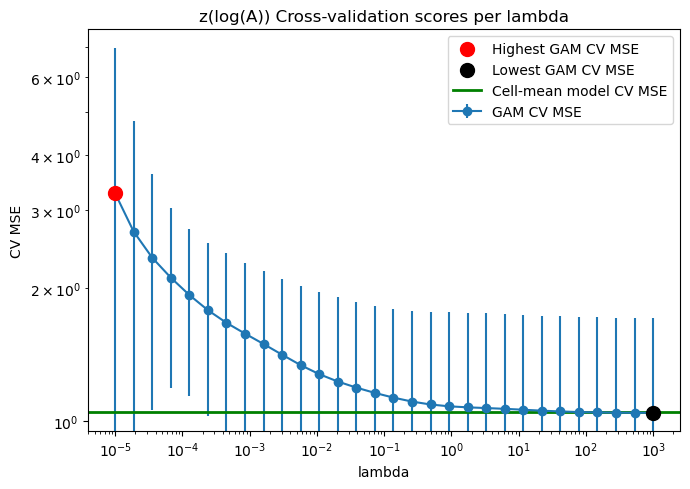

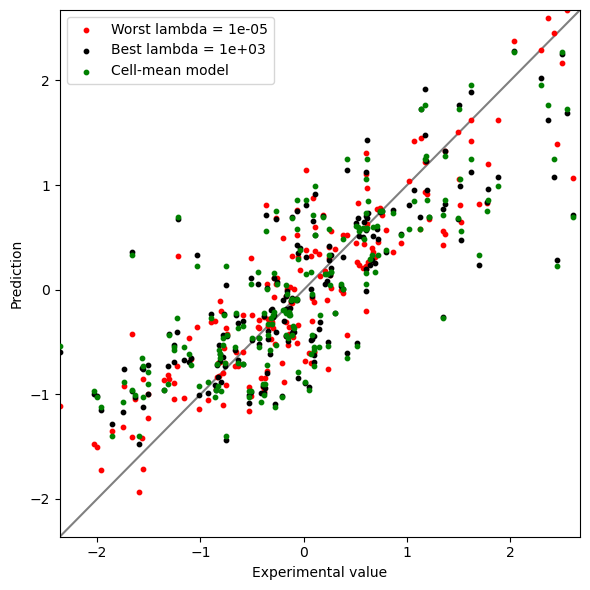

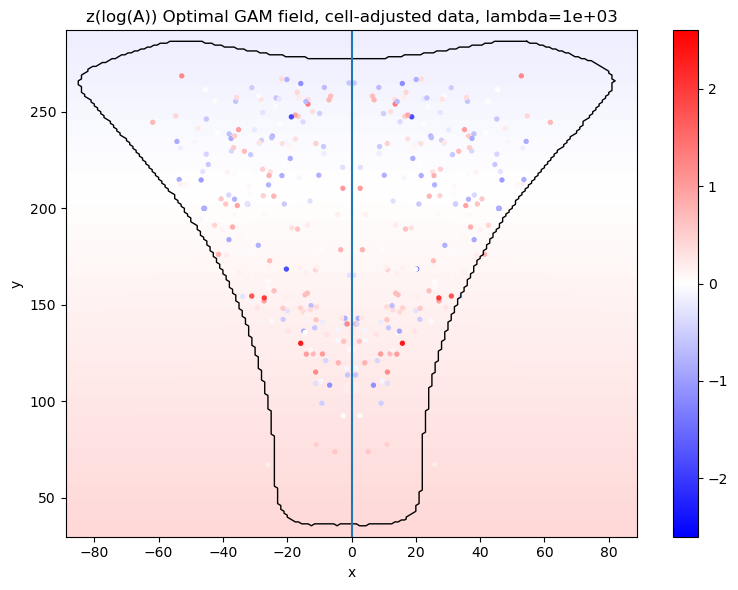

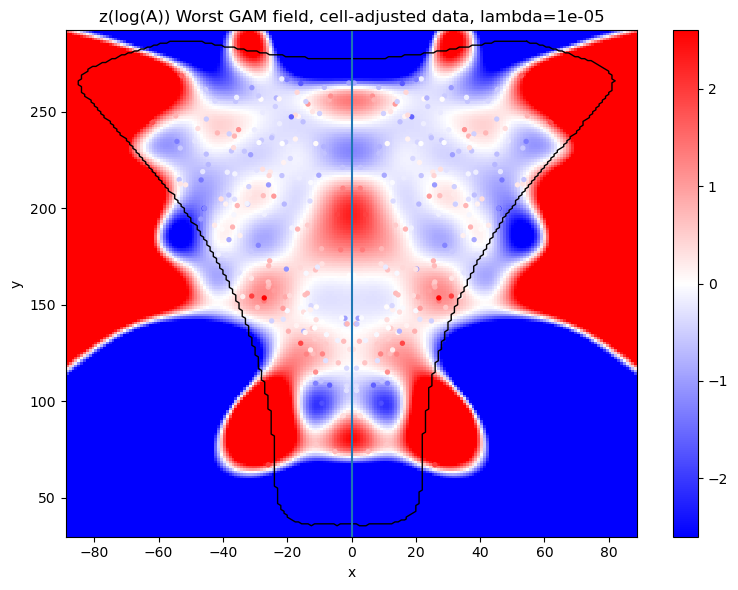

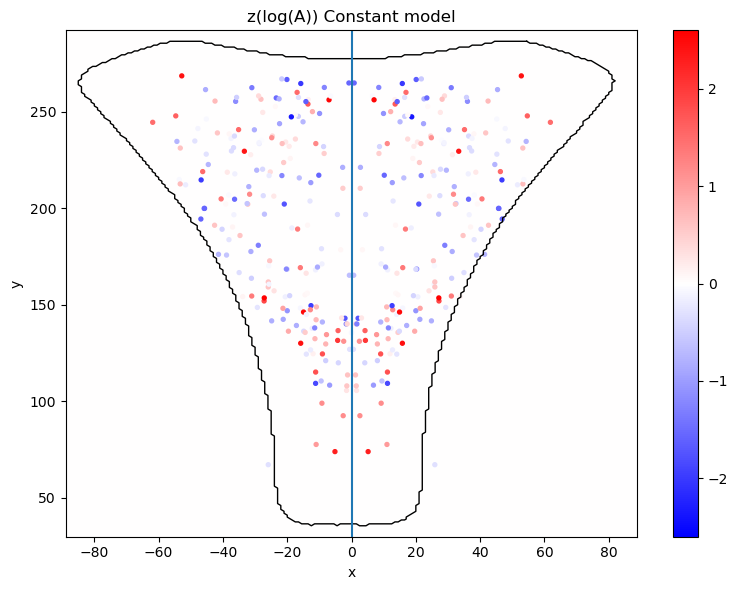

In [5]:
lims = [
    min(
        F.min(),
        F_fit_best.min(),
        F_fit_worst.min(),
        F_fit_constant.min(),
    ),
    max(
        F.max(),
        F_fit_best.max(),
        F_fit_worst.max(),
        F_fit_constant.max(),
    ),
]

nx = 200
ny = 200

x_grid = np.linspace(
    edge_knots[0][0],
    edge_knots[0][1],
    nx,
)

y_grid = np.linspace(
    edge_knots[1][0],
    edge_knots[1][1],
    ny,
)

xx, yy = np.meshgrid(
    x_grid,
    y_grid,
)

X_grid = np.column_stack([
    xx.ravel(),
    yy.ravel(),
])

F_grid_best = predict_field(gam_best, X_grid).reshape(ny, nx)
F_grid_worst = predict_field(gam_worst, X_grid).reshape(ny, nx)
F_grid_constant = np.full(
    (ny, nx),
    constant_value,
)

fig, ax = plt.subplots(figsize=(7, 5))

ax.errorbar(
    lambda_grid,
    mean_mse,
    yerr=std_mse,
    marker="o",
    label="GAM CV MSE",
)

ax.scatter(
    worst_lam,
    mean_mse[worst_idx],
    s=100,
    color="red",
    zorder=10,
    label="Highest GAM CV MSE",
)

ax.scatter(
    best_lam,
    mean_mse[best_idx],
    s=100,
    color="black",
    zorder=11,
    label="Lowest GAM CV MSE",
)

ax.axhline(
    constant_cv_mse,
    color="green",
    linewidth=2,
    label="Cell-mean model CV MSE",
)

ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("lambda")
ax.set_ylabel("CV MSE")
ax.set_title(f"{F_name} Cross-validation scores per lambda")
ax.legend()

fig.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(6, 6))

ax.scatter(
    F,
    F_fit_worst,
    s=10,
    color="red",
    label=f"Worst lambda = {worst_lam:.3g}",
    zorder=1,
)

ax.scatter(
    F,
    F_fit_best,
    s=10,
    color="black",
    label=f"Best lambda = {best_lam:.3g}",
    zorder=2,
)

ax.scatter(
    F,
    F_fit_constant,
    s=10,
    color="green",
    label="Cell-mean model",
    zorder=3,
)

ax.plot(
    lims,
    lims,
    "-",
    color="grey",
    zorder=0,
)

ax.set_xlim(lims)
ax.set_ylim(lims)
ax.set_xlabel("Experimental value")
ax.set_ylabel("Prediction")
ax.legend()

fig.tight_layout()
plt.show()

vmax = np.max(np.abs(F_sym))
vmin = -vmax

fig, ax = plt.subplots(figsize=(8, 6))

im = ax.pcolormesh(
    xx,
    yy,
    F_grid_best,
    shading="auto",
    cmap="bwr",
    vmin=vmin,
    vmax=vmax,
)

ax.scatter(
    x_sym,
    y_sym,
    s=8,
    c=F_adj_best_sym,
    cmap="bwr",
    vmin=vmin,
    vmax=vmax,
)

ax.plot(
    border_x,
    border_y,
    "-k",
    lw=1,
)


ax.axvline(0)

ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_title(f"{F_name} Optimal GAM field, cell-adjusted data, lambda={best_lam:.3g}")

fig.colorbar(im, ax=ax)
fig.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(8, 6))

im = ax.pcolormesh(
    xx,
    yy,
    F_grid_worst,
    shading="auto",
    cmap="bwr",
    vmin=vmin,
    vmax=vmax,
)

ax.scatter(
    x_sym,
    y_sym,
    s=8,
    c=F_adj_worst_sym,
    cmap="bwr",
    vmin=vmin,
    vmax=vmax,
)

ax.plot(
    border_x,
    border_y,
    "-k",
    lw=1,
)


ax.axvline(0)

ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_title(f"{F_name} Worst GAM field, cell-adjusted data, lambda={worst_lam:.3g}")

fig.colorbar(im, ax=ax)
fig.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(8, 6))

im = ax.pcolormesh(
    xx,
    yy,
    F_grid_constant,
    shading="auto",
    cmap="bwr",
    vmin=vmin,
    vmax=vmax,
)

ax.scatter(
    x_sym,
    y_sym,
    s=8,
    c=F_sym,
    cmap="bwr",
    vmin=vmin,
    vmax=vmax,
)

ax.plot(
    border_x,
    border_y,
    "-k",
    lw=1,
)

ax.axvline(0)

ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_title(f"{F_name} Constant model")

fig.colorbar(im, ax=ax)
fig.tight_layout()
plt.show()

# Nested Cross Validation

In [6]:
n_splines = 15
n_outer_folds = 15
n_inner_folds = 30

lambda_grid = np.logspace(-5, 3, 25)

X = np.column_stack([x, y])

x_domain = np.concatenate([
    x,
    -x,
    border_x,
    -border_x,
])

y_domain = np.concatenate([
    y,
    border_y,
])

x_min = np.min(x_domain)
x_max = np.max(x_domain)
y_min = np.min(y_domain)
y_max = np.max(y_domain)

x_pad = 0.02 * (x_max - x_min)
y_pad = 0.02 * (y_max - y_min)

edge_knots = [
    [x_min - x_pad, x_max + x_pad],
    [y_min - y_pad, y_max + y_pad],
]

outer_gam_mse = []
outer_constant_mse = []
outer_delta = []
selected_lambdas = []

F_pred_gam_oof = np.full(len(F), np.nan)
F_pred_constant_oof = np.full(len(F), np.nan)

outer_splits = cell_kfold(
    cell,
    n_splits=n_outer_folds,
    seed=42,
)

assert len(outer_splits) == n_outer_folds

for outer_fold, (train_idx, test_idx) in enumerate(
    tqdm(outer_splits, desc="Outer CV")
):
    x_train_outer = x[train_idx]
    y_train_outer = y[train_idx]
    cell_train_outer = cell[train_idx]
    F_train_outer = F[train_idx]

    x_test = x[test_idx]
    y_test = y[test_idx]
    cell_test = cell[test_idx]
    F_test = F[test_idx]

    inner_splits = cell_kfold(
        cell_train_outer,
        n_splits=n_inner_folds,
        seed=1000 + outer_fold,
    )

    inner_lambda_mse = []

    for lam in lambda_grid:
        inner_fold_mse = []

        for inner_train_idx, inner_val_idx in inner_splits:
            gam_inner = fit_gam_cells(
                lam,
                x_train_outer[inner_train_idx],
                y_train_outer[inner_train_idx],
                cell_train_outer[inner_train_idx],
                F_train_outer[inner_train_idx],
            )

            F_val_pred = predict_gam_cells(
                gam_inner,
                x_train_outer[inner_val_idx],
                y_train_outer[inner_val_idx],
                cell_train_outer[inner_val_idx],
            )

            inner_fold_mse.append(
                mean_squared_error(
                    F_train_outer[inner_val_idx],
                    F_val_pred,
                )
            )

        inner_lambda_mse.append(
            np.mean(inner_fold_mse)
        )

    inner_lambda_mse = np.array(inner_lambda_mse)

    best_inner_idx = np.argmin(inner_lambda_mse)
    best_lam = lambda_grid[best_inner_idx]

    selected_lambdas.append(best_lam)

    gam_outer = fit_gam_cells(
        best_lam,
        x_train_outer,
        y_train_outer,
        cell_train_outer,
        F_train_outer,
    )

    F_test_pred_gam = predict_gam_cells(
        gam_outer,
        x_test,
        y_test,
        cell_test,
    )

    F_test_pred_constant = cell_mean_prediction(
        F_train_outer,
        cell_train_outer,
        cell_test,
    )

    gam_mse = mean_squared_error(
        F_test,
        F_test_pred_gam,
    )

    constant_mse = mean_squared_error(
        F_test,
        F_test_pred_constant,
    )

    delta = constant_mse - gam_mse

    outer_gam_mse.append(gam_mse)
    outer_constant_mse.append(constant_mse)
    outer_delta.append(delta)

    F_pred_gam_oof[test_idx] = F_test_pred_gam
    F_pred_constant_oof[test_idx] = F_test_pred_constant

outer_gam_mse = np.array(outer_gam_mse)
outer_constant_mse = np.array(outer_constant_mse)
outer_delta = np.array(outer_delta)
selected_lambdas = np.array(selected_lambdas)

mean_gam_mse = np.mean(outer_gam_mse)
mean_constant_mse = np.mean(outer_constant_mse)

mean_delta = np.mean(outer_delta)
std_delta = np.std(outer_delta, ddof=1)
sem_delta = std_delta / np.sqrt(n_outer_folds)

tcrit = t.ppf(
    0.975,
    df=n_outer_folds - 1,
)

ci_low = mean_delta - tcrit * sem_delta
ci_high = mean_delta + tcrit * sem_delta

relative_improvement = mean_delta / mean_constant_mse

fold_number = np.arange(1, n_outer_folds + 1)

lims = [
    min(
        F.min(),
        F_pred_gam_oof.min(),
        F_pred_constant_oof.min(),
    ),
    max(
        F.max(),
        F_pred_gam_oof.max(),
        F_pred_constant_oof.max(),
    ),
]

print("Nested CV GAM + cell biases MSE:", mean_gam_mse)
print("Nested CV cell-mean MSE:", mean_constant_mse)
print()
print("Mean delta:", mean_delta)
print("Delta std:", std_delta)
print("Delta SEM:", sem_delta)
print("95% CI for delta:", (ci_low, ci_high))
print()
print("Relative MSE improvement:", relative_improvement)
print()
print("Selected lambdas:", selected_lambdas)
print("Median selected lambda:", np.median(selected_lambdas))


Outer CV:   0%|          | 0/15 [00:00<?, ?it/s]

Nested CV GAM + cell biases MSE: 1.0507372030687505
Nested CV cell-mean MSE: 1.0401792155888703

Mean delta: -0.010557987479880326
Delta std: 0.09291796132464124
Delta SEM: 0.023991314451592024
95% CI for delta: (np.float64(-0.06201423934130493), np.float64(0.04089826438154427))

Relative MSE improvement: -0.010150161935223055

Selected lambdas: [1000. 1000.    1. 1000. 1000. 1000. 1000. 1000. 1000. 1000. 1000. 1000.
 1000. 1000. 1000.]
Median selected lambda: 1000.0


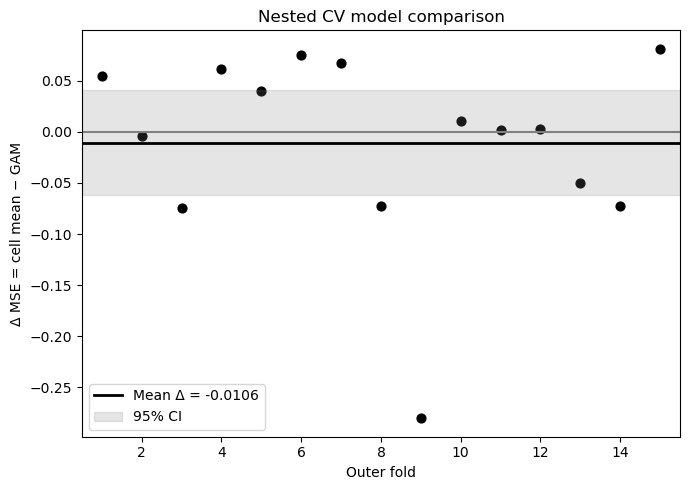

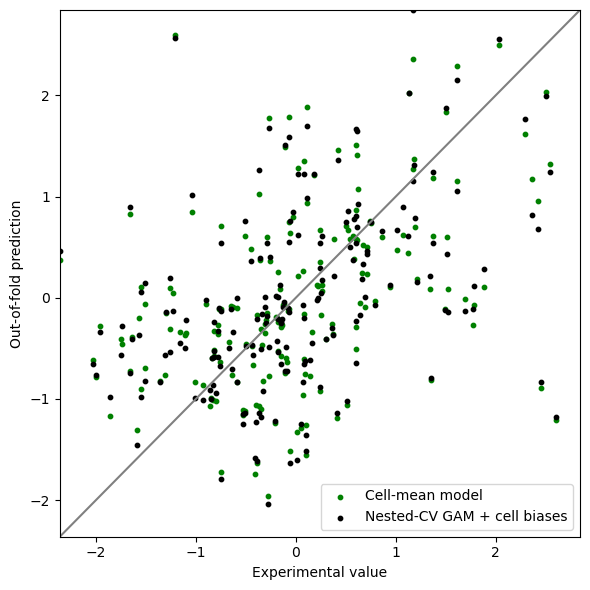

In [7]:
''' Plotting '''

fig, ax = plt.subplots(figsize=(7, 5))

ax.axhline(
    0,
    color="grey",
    linestyle="-",
)

ax.scatter(
    fold_number,
    outer_delta,
    s=40,
    color="black",
)

ax.axhline(
    mean_delta,
    color="black",
    linewidth=2,
    label=f"Mean Δ = {mean_delta:.3g}",
)

ax.fill_between(
    [0.5, n_outer_folds + 0.5],
    ci_low,
    ci_high,
    color="grey",
    alpha=0.2,
    label="95% CI",
)

ax.set_xlim(0.5, n_outer_folds + 0.5)
ax.set_xlabel("Outer fold")
ax.set_ylabel("Δ MSE = cell mean − GAM")
ax.set_title("Nested CV model comparison")
ax.legend()

fig.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(6, 6))

ax.scatter(
    F,
    F_pred_constant_oof,
    s=10,
    color="green",
    label="Cell-mean model",
    zorder=1,
)

ax.scatter(
    F,
    F_pred_gam_oof,
    s=10,
    color="black",
    label="Nested-CV GAM + cell biases",
    zorder=2,
)

ax.plot(
    lims,
    lims,
    "-",
    color="grey",
)

ax.set_xlim(lims)
ax.set_ylim(lims)

ax.set_xlabel("Experimental value")
ax.set_ylabel("Out-of-fold prediction")
ax.legend()

fig.tight_layout()
plt.show()

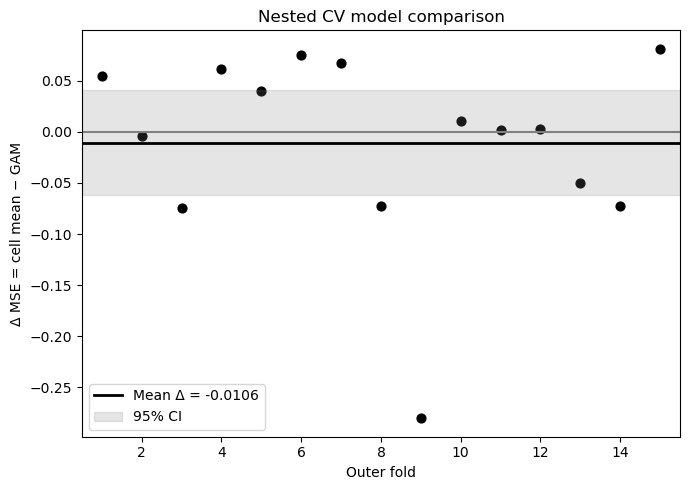

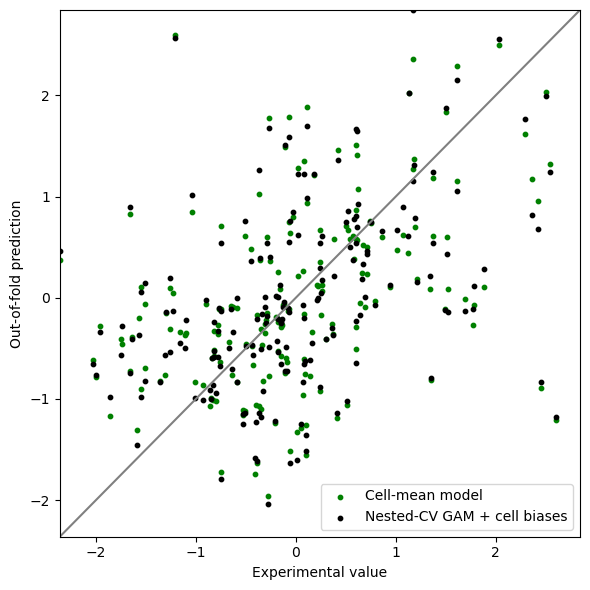

In [8]:
import pickle
import numpy as np
import matplotlib.pyplot as plt

output_file = "../output/dataset_Ax_ME.pkl"

outer_delta_export = np.asarray(outer_delta, dtype=float)

with open(output_file, "wb") as f:
    pickle.dump(outer_delta_export, f)


fig, ax = plt.subplots(figsize=(7, 5))

ax.axhline(
    0,
    color="grey",
    linestyle="-",
)

ax.scatter(
    fold_number,
    outer_delta,
    s=40,
    color="black",
)

ax.axhline(
    mean_delta,
    color="black",
    linewidth=2,
    label=f"Mean Δ = {mean_delta:.3g}",
)

ax.fill_between(
    [0.5, n_outer_folds + 0.5],
    ci_low,
    ci_high,
    color="grey",
    alpha=0.2,
    label="95% CI",
)

ax.set_xlim(0.5, n_outer_folds + 0.5)
ax.set_xlabel("Outer fold")
ax.set_ylabel("Δ MSE = cell mean − GAM")
ax.set_title("Nested CV model comparison")
ax.legend()

fig.tight_layout()
plt.show()


fig, ax = plt.subplots(figsize=(6, 6))

ax.scatter(
    F,
    F_pred_constant_oof,
    s=10,
    color="green",
    label="Cell-mean model",
    zorder=1,
)

ax.scatter(
    F,
    F_pred_gam_oof,
    s=10,
    color="black",
    label="Nested-CV GAM + cell biases",
    zorder=2,
)

ax.plot(
    lims,
    lims,
    "-",
    color="grey",
)

ax.set_xlim(lims)
ax.set_ylim(lims)

ax.set_xlabel("Experimental value")
ax.set_ylabel("Out-of-fold prediction")
ax.legend()

fig.tight_layout()
plt.show()

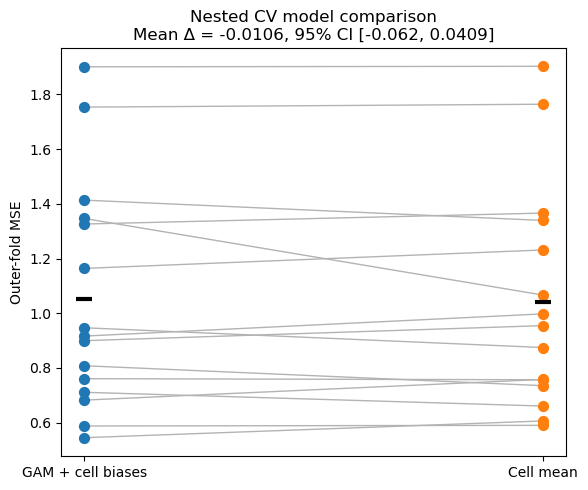

In [9]:
fig, ax = plt.subplots(figsize=(6, 5))

x_gam = np.zeros(n_outer_folds)
x_constant = np.ones(n_outer_folds)

for i in range(n_outer_folds):
    ax.plot(
        [0, 1],
        [outer_gam_mse[i], outer_constant_mse[i]],
        color="0.7",
        linewidth=1,
        zorder=1,
    )

ax.scatter(
    x_gam,
    outer_gam_mse,
    s=50,
    label="GAM",
    zorder=2,
)

ax.scatter(
    x_constant,
    outer_constant_mse,
    s=50,
    label="Cell mean",
    zorder=2,
)

ax.scatter(
    [0, 1],
    [mean_gam_mse, mean_constant_mse],
    s=140,
    marker="_",
    linewidth=3,
    color="k",
    label="Mean",
    zorder=3,
)

ax.set_xticks([0, 1])
ax.set_xticklabels(["GAM + cell biases", "Cell mean"])
ax.set_ylabel("Outer-fold MSE")
ax.set_title(
    f"Nested CV model comparison\n"
    f"Mean Δ = {mean_delta:.3g}, 95% CI [{ci_low:.3g}, {ci_high:.3g}]"
)

#ax.legend()

fig.tight_layout()
plt.show()

In [10]:
t_stat, p_value = ttest_1samp(
    outer_delta,
    popmean=0.0,
    alternative="greater",
)

print("Mean Δ MSE:", np.mean(outer_delta))
print("t statistic:", t_stat)
print("one-sided p value:", p_value)

if p_value < 0.05:
    print("GAM has significantly lower MSE than the cell-mean model.")
else:
    print("No significant evidence that the GAM has lower MSE than the cell-mean model.")

Mean Δ MSE: -0.010557987479880326
t statistic: -0.4400754073389136
one-sided p value: 0.6666997845319451
No significant evidence that the GAM has lower MSE than the cell-mean model.
